**IMPORTANT DECISION**
- A fixed random seed = 42 will be used for Python, NumPy and Pytorch.
- Randomness is involved in multiple stages of a Deep Learning workflow (datasplitting, weight updates etc.)
- Using a fixed seed ensures consistency and reproducibillity of the pipeline

In [28]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch

# Check if there is a GPU available for performance improvement
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Reproducibility Things
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print(f"Random seed set to {SEED}.")

Using device: cpu
Random seed set to 42.


## Setting Up Dataframe

### Dataset Loading
The assignment provides a subset data already with predefined training, validation and test splits. So most of the data splitting has already been done for us.

We simply now merge the corresponding annotations into a single dataframe per **split (training, dev etc)**, retaining the original text and character offsets required for span detection. 
- **val_df** will be utilised for hyperparameter tuning
- **test_df** will be utilised for final model evaluation

In [29]:
DATA_DIR = Path("data")

def load_split(split):
    task1 = pd.DataFrame(json.loads((DATA_DIR / f"{split}_set_task1.txt").read_text(encoding="utf-8")))
    task2 = pd.DataFrame(json.loads((DATA_DIR / f"{split}_set_task2.txt").read_text(encoding="utf-8")))

    task2 = task2.rename(columns={"labels": "spans"})
    df = task1.merge(task2, on=["id", "text"], validate="one_to_one")

    assert len(df) == len(task1) == len(task2), f"Mismatched {split} annotations"
    return df[["id", "text", "labels", "spans"]]

train_df = load_split("training")
val_df = load_split("dev")
test_df = load_split("test")

print(f"Training: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

display(train_df.head(3))

Training: 688
Validation: 63
Test: 200


,id,text,labels,spans
0,128,THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n,[Black-and-white Fallacy/Dictatorship],"[{'start': 0, 'end': 41, 'technique': 'Black-a..."
1,189,This is not an accident!,[],[]
2,96,SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...,"[Loaded Language, Name calling/Labeling, Sloga...","[{'end': 83, 'start': 47, 'technique': 'Slogan..."


### Dataset Integrity and Leakage Analysis

we must now investigate overlapping meme identifiers and identical texts across splits.

Checking for duplicate instances across splits is curcial since a model evaluated on previously encountered text may produce **misleadingly optimistic results** as a result of **data leakage**. The following check determines whether corrective preprocessing is necessary before proceeding:

In [30]:
splits = {"Train": train_df, "Validation": val_df, "Test": test_df}

overlap_check = pd.DataFrame([
    {
        "Splits": f"{a} vs {b}",
        "Shared IDs": len(set(splits[a]["id"]) & set(splits[b]["id"])),
        "Identical texts": len(set(splits[a]["text"]) & set(splits[b]["text"]))
    }
    for a, b in [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]
])

held_out_texts = set(val_df["text"]) | set(test_df["text"])

duplicate_rows = train_df.loc[train_df["text"].isin(held_out_texts), ["id", "text"]]

display(overlap_check, duplicate_rows)

,Splits,Shared IDs,Identical texts
0,Train vs Validation,0,0
1,Train vs Test,1,1
2,Validation vs Test,0,0


,id,text
436,474_batch_2,JOE BIDEN'S LIFETIME ACCOMPLISHMENTS.


### Preventing Data Leakage

The integrity analysis identified **one** identical meme appearing in both training and test set. Because our model predicts from text alone, retaining this example in training would compromise the independence of the test evaluation.

We therefore remove only the overlapping training instance, reducing the training set from 688 to 687 examples. This reduces training data by only **0.15%**, a negligible loss compared with the importance of reliable performance estimates.

In [31]:
# Remove training examples found in test.
train_df = train_df.loc[~train_df["text"].isin(held_out_texts)].reset_index(drop=True)

# Verify split independence.
assert set(train_df["text"]).isdisjoint(held_out_texts)
assert set(train_df["id"]).isdisjoint(set(val_df["id"]) | set(test_df["id"]))
assert set(val_df["text"]).isdisjoint(set(test_df["text"]))

print(f"Training: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

Training: 687
Validation: 63
Test: 200


### Target Encoding
Since each meme can contain multiple persuasion techniques, we convert its labels into a 20-element multi-hot vector, where 1 indicates that a technique is present and 0 indicates its absence. 

This prepares the labels for multi-label classification using a neural network.

In [32]:
# 20 persuasion techniques from training data.
LABELS = sorted({label for labels in train_df["labels"] for label in labels})
assert len(LABELS) == 20

label_to_id = {label: i for i, label in enumerate(LABELS)}

# Ensure evaluation splits contain no unseen techniques.
assert all(set(labels).issubset(label_to_id) for df in (val_df, test_df) for labels in df["labels"])

# Convert classification labels into multi-hot vectors.
for df in (train_df, val_df, test_df):
    df["targets"] = df["labels"].apply(lambda labels: [int(label in labels) for label in LABELS])

display(train_df.head(3))

,id,text,labels,spans,targets
0,128,THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n,[Black-and-white Fallacy/Dictatorship],"[{'start': 0, 'end': 41, 'technique': 'Black-a...","[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,189,This is not an accident!,[],[],"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,96,SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...,"[Loaded Language, Name calling/Labeling, Sloga...","[{'end': 83, 'start': 47, 'technique': 'Slogan...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, ..."


# Exploratory Data Analysis

## Dataset Overview

In [33]:
def summarise(df):
    labels_per_meme = df["labels"].map(len)
    return pd.Series({
        "Memes": len(df),
        "Annotated labels": labels_per_meme.sum(),
        "Mean labels/meme": round(labels_per_meme.mean(), 2),
        "Memes with no labels": labels_per_meme.eq(0).sum(),
        "Median words": df["text"].str.split().map(len).median()
    })

summary = pd.DataFrame({"Train": summarise(train_df), "Validation": summarise(val_df)}).T

display(summary)

,Memes,Annotated labels,Mean labels/meme,Memes with no labels,Median words
Train,687.0,1184.0,1.72,142.0,15.0
Validation,63.0,123.0,1.95,15.0,15.0


The dataset contains only **687** training memes and **63** validation memes. This limited sample size increases the risk of **overfitting** and makes validation estimates less reliable. We will therefore investigate data-efficient techniques such as **transfer learning**, frozen encoder vs staged fine-tuning or other parameter-efficient methods such as **LoRA**. Additional public training data and carefully designed augmentation **may** also be considered, given label consistency and data integrity are preserved, which can be challenging and even small mistakes can lead to poor model generelisabillity. 

We will determine the most suitable approaches after further EDA and compare them experimentally. As of now:

**IMPORTANT DESIGN DECISION** 

Given memes can have multiple techniques or none, **sigmoid classification** with **binary cross-entropy (BCE)** are appropriate. Unlike softmax, this allows each technique to be predicted independently, supporting multiple or zero predicted labels.

## Class Distribution & Imbalance 

Given class imbalance can cause the models to become biased towards higher majority classes and often ignore minority classes, we must carefully check for this imbalance so if needed, appropriate adjustments to the model's weights can be made to ensure minority labels are given approximately equal consideration.

,Train,Train prevalence (%),Validation
Loaded Language,358,52.1,31
Name calling/Labeling,218,31.7,29
Smears,200,29.1,18
Exaggeration/Minimisation,52,7.6,7
Doubt,48,7.0,8
Slogans,44,6.4,3
Appeal to fear/prejudice,43,6.3,4
Whataboutism,40,5.8,4
Glittering generalities (Virtue),32,4.7,1
Causal Oversimplification,27,3.9,1


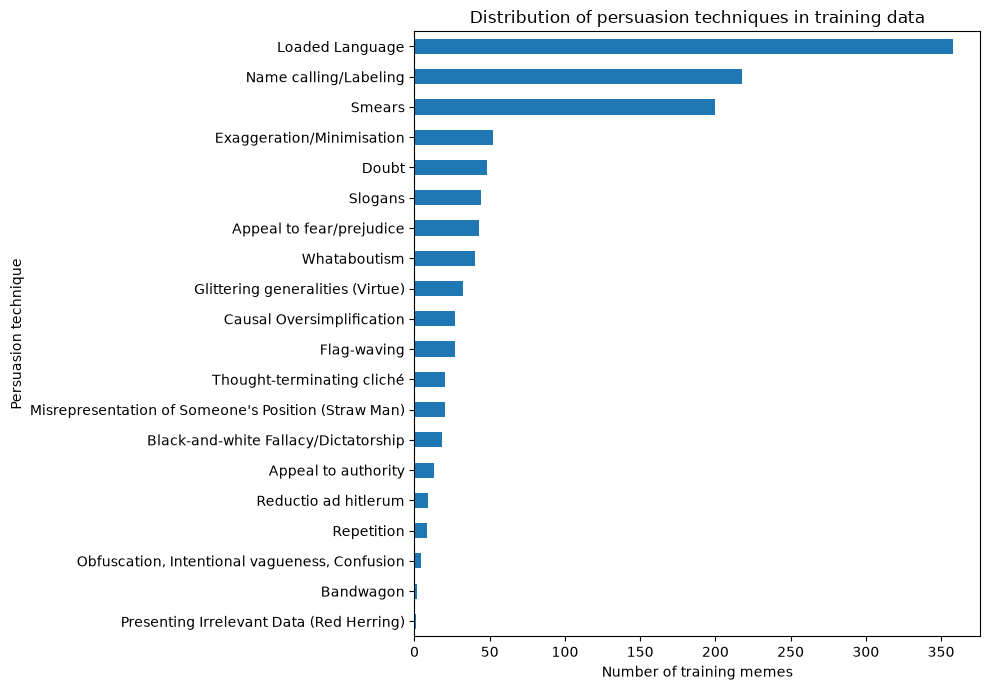

In [34]:
train_targets = pd.DataFrame(train_df["targets"].tolist(), columns=LABELS)
val_targets = pd.DataFrame(val_df["targets"].tolist(), columns=LABELS)

train_support = train_targets.sum().sort_values(ascending=False)
val_support = val_targets.sum().reindex(train_support.index)

label_stats = pd.DataFrame({
    "Train": train_support,
    "Train prevalence (%)": (100 * train_support / len(train_df)).round(1),
    "Validation": val_support
})

display(label_stats)

fig, ax = plt.subplots(figsize=(10, 7))
train_support.sort_values().plot.barh(ax=ax)

ax.set(xlabel="Number of training memes", ylabel="Persuasion technique", title="Distribution of persuasion techniques in training data")
plt.tight_layout()
plt.show()

As can be seen, The training distribution is **severely imbalanced**. Loaded Language appears in **358** of **687** memes, whereas Presenting Irrelevant Data (Red Herring), Bandwagon and Obfuscation have only 1, 2 and 4 training examples respectively.

This is an issue since high overall performance can easily hide poor recognition of rare technqiues. 

Further also note how the validation set is missing **3** techniques, making their individual performance difficult to assess reliably. Additionally, since the training data is highly imbalanced, we will have to compare standard BCE with an imbalance-aware loss to investigate whether it improves recognition of underrepresented techniques. However, improvements must be interpreted very **cautiously** given the limited validation coverage.

**IMPORTANT DESIGN DECISION**

As a result of this strong imbalance, we will use **micro-F1** as our **primary classification metric**, which is also consistent with the official SemEval evaluation, while we will additonally report **macro-F1** and per-technique **precision**, **recall** and **F1** to expose weaknesses on less frequent labels.

## Label Cardinality

This will show us how many techniques occur together for one meme example:

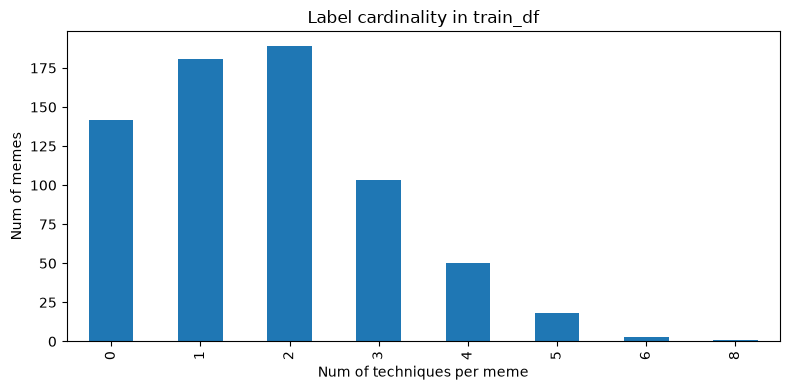

Mean label cardinality: 1.72
Memes with no techniques: 142
Memes with multiple techniques: 364


In [35]:
cardinality = train_df["labels"].map(len)

fig, ax = plt.subplots(figsize=(8, 4))
cardinality.value_counts().sort_index().plot.bar(ax=ax)

ax.set(xlabel="Num of techniques per meme", ylabel="Num of memes", title="Label cardinality in train_df")
plt.tight_layout()
plt.show()

print(f"Mean label cardinality: {cardinality.mean():.2f}")
print(f"Memes with no techniques: {cardinality.eq(0).sum()}")
print(f"Memes with multiple techniques: {cardinality.gt(1).sum()}")

Once again we realise that of the 687 training memes, 364 contain multiple techniques, while 142 contain **none**. 

Our model must therefore support predicting multiple labels **OR** no labels at all, rather than forcing a single prediction. 

**IMPORTANT DESIGN DECISION** 

buulding onto the previous decision, we will use a multi-label classification head with 20 sigmoid outputs, allowing each technique to receive its own score without forcing the scores to sum to one. We will use binary cross-entropy (BCE) to train these predictions. Later, we will have to investigate how best to convert these scores into final labels using limited validation data.

## Text-Length Analysis

We analyse text lengths to understand how much text our model needs to process. This helps us choose a suitable input length, ensuring important information is not cut off while avoiding unnecessary computation. Once we select a pretrained model, we will check its token lengths to make the final decision.

,Split,Median words,Max words,Median characters,Max characters,Multiline (%),All-caps (%)
0,Train,15.0,72,86.0,427,85.9,47.5
1,Validation,15.0,49,93.0,273,87.3,39.7


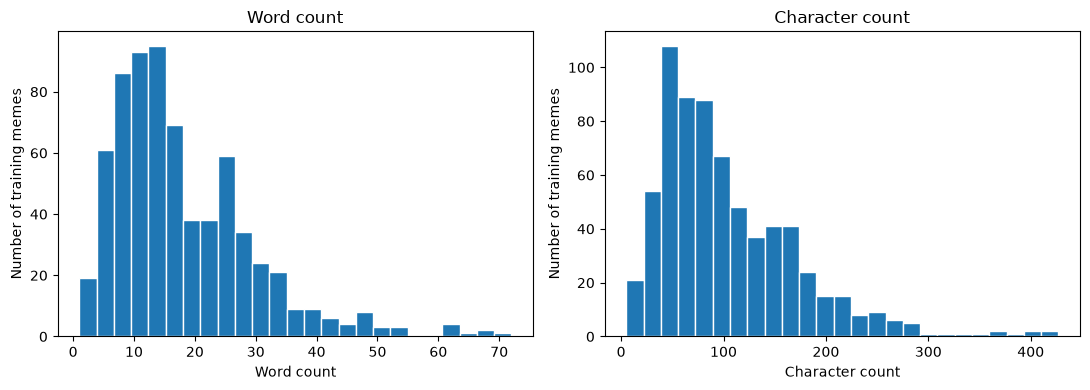

In [36]:
length_summary = []

for name, df in [("Train", train_df), ("Validation", val_df)]:
    words = df["text"].str.split().map(len)
    chars = df["text"].str.len()

    length_summary.append({
        "Split": name,
        "Median words": words.median(),
        "Max words": words.max(),
        "Median characters": chars.median(),
        "Max characters": chars.max(),
        "Multiline (%)": round(100 * df["text"].str.contains("\n", regex=False).mean(), 1),
        "All-caps (%)": round(100 * np.mean(["".join(c for c in t if c.isalpha()).isupper() for t in df["text"]]), 1)
    })

display(pd.DataFrame(length_summary))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, values, title in zip(axes, [train_df["text"].str.split().map(len), train_df["text"].str.len()], ["Word count", "Character count"]):
    ax.hist(values, bins=25, edgecolor="white")
    ax.set(xlabel=title, ylabel="Number of training memes", title=title)

plt.tight_layout()
plt.show()

Observing the results, training memes are relatively short, with a median of 15 words, and 95% containing 39 words or fewer. This suggests a smaller pretrained transformer may be suitable, reducing computational costs. However, we will check the actual token lengths before deciding on the model's input size to avoid cutting off important text. 

## Span Analysis

For Part B, our future model must identify the specific phrases/word associated with each persuasion technique. We will investigate how much text these annotations cover and whether different techniques are typically expressed through short phrases or longer passages. 

This will help us choose a suitable approach for span detection.

,Spans,Median_characters,Median_coverage_pct
Technique,,,
Smears,202,83.0,96.1
Whataboutism,40,128.5,95.0
Misrepresentation of Someone's Position (Straw Man),20,91.5,63.9
Causal Oversimplification,29,75.0,63.3
Doubt,49,64.0,62.0
Glittering generalities (Virtue),33,58.0,54.5
Appeal to fear/prejudice,46,42.5,39.0
Exaggeration/Minimisation,59,26.0,28.3
Flag-waving,33,22.0,20.3


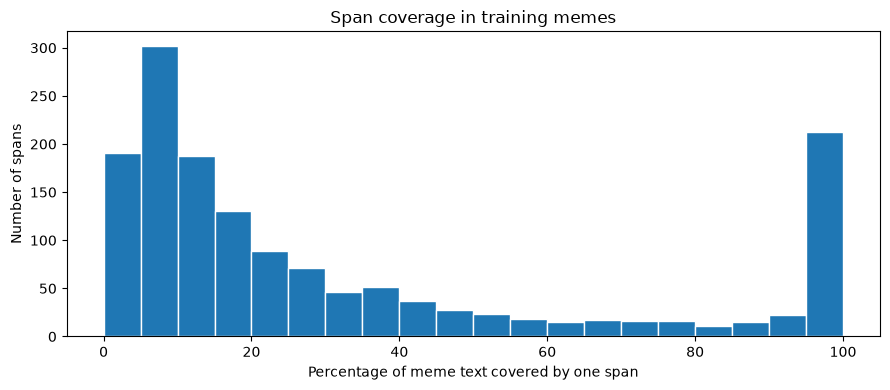

In [37]:
span_df = pd.DataFrame([
    {
        "Technique": s["technique"],
        "Span characters": s["end"] - s["start"],
        "Text covered (%)": 100 * (s["end"] - s["start"]) / len(row.text)
    }
    for row in train_df.itertuples()
    for s in row.spans
])

span_summary = (span_df.groupby("Technique")
    .agg(Spans=("Technique", "size"), Median_characters=("Span characters", "median"), Median_coverage_pct=("Text covered (%)", "median"))
    .query("Spans >= 20")
    .sort_values("Median_coverage_pct", ascending=False)
    .round(1)
)

display(span_summary)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(span_df["Text covered (%)"], bins=np.arange(0, 105, 5), edgecolor="white")
ax.set(xlabel="Percentage of meme text covered by one span", ylabel="Number of spans", title="Span coverage in training memes")
plt.tight_layout()
plt.show()

The results show that span lengths vary considerably; Some annotations cover short phrases, while others cover nearly the entire meme

**IMPORTANT DESIGN CONSIDERATION**

The Part B model must accurately identify both short phrases and longer passages. We must investigate context-aware token-level span detection, which allows the model to consider **surrounding words**. We must also evaluate span detection separately; identifying the correct technique does not guarantee highlighting the correct text.